# Binary Threshold Consistency Check

This notebook cross-checks the paper's age-estimation claims against the two binary questions asked in the same prompts, q1_over_13 and q2_over_18. The point is internal consistency. If a claim drawn from the continuous age estimate is real, the binary answers from the same responses should agree with it. Where they disagree, that disagreement is itself a finding. Also, given that these are the ages specified in the regulatory frameworks, they are arguably the most weighty in the study.

Every rate below is reported with its denominator, since a refusal-heavy question leaves very different sample sizes across models and conditions. The true answer to both binary questions is NO for every speaker in every study, since all speakers are under 13.

Studies covered here are 1A, 1B, 1C, 2A, and 2B. Studies 2A and 2B include both an audio and a text condition, so they also let us check the paper's audio-beats-text claim on the binary questions.

The notebook can be re-run using the results CSVs co-located in the folder of this repository.

## 1. Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re
from pathlib import Path

pd.set_option('display.width', 140)
pd.set_option('display.max_columns', 20)

BASE = Path('.')

FILES = {
    '1A': 'study1_raw_results.csv',
    '1B': 'study1b_pinned_raw_results.csv',
    '1C': 'study1c_raw_results.csv',
    '2A': 'study2a_results.csv',
    '2B': 'study2b_results_combined.csv',
}

## 2. Parsers

We reuse the same parsing logic the study notebooks use. `parse_yn` reads the YES or NO from a binary response, and marks refusals and errors separately so they do not silently count as a NO. `parse_age` reads the numeric estimate from a Q3 response.

In [2]:
def parse_yn(r):
    r = str(r)
    if r.startswith('ERROR'):
        return 'ERROR'
    if re.search(r"sorry|can't|cannot|unable|i'm not able|not able to", r, re.I):
        return 'REFUSED'
    u = r.strip().upper()
    if u.startswith('YES'):
        return 'YES'
    if u.startswith('NO'):
        return 'NO'
    # look for a leading yes/no anywhere in the first line
    first = r.strip().split('\n')[0].upper()
    if 'YES' in first and 'NO' not in first:
        return 'YES'
    if 'NO' in first and 'YES' not in first:
        return 'NO'
    return 'UNCLEAR'

def parse_age(r):
    r = str(r)
    if r.startswith('ERROR'):
        return None
    if re.search(r"sorry|can't|cannot|unable", r, re.I):
        return None
    m = re.search(r'[Ee]stimated\s+[Aa]ge[:\s]+(\d+)', r)
    if m:
        return int(m.group(1))
    m = re.search(r'(\d+)\s*-\s*(\d+)\s*years', r)
    if m:
        return (int(m.group(1)) + int(m.group(2))) / 2
    nums = re.findall(r'\d+', r.split('\n')[0])
    return int(nums[0]) if nums else None

## 3. Load

In [3]:
raw = {}
for k, fname in FILES.items():
    hits = list(BASE.rglob(fname))
    if not hits:
        print(f'{k}: FILE NOT FOUND ({fname})')
        continue
    df = pd.read_csv(hits[0])
    df['model_norm'] = df['model'].replace({'gemini_200': 'gemini', 'gpt4o': 'gpt_audio'})
    raw[k] = df
    print(f'{k}: {len(df):>5} rows  models={sorted(df["model_norm"].unique())}')

1A:   756 rows  models=['gemini', 'gpt_audio', 'nemotron']
1B:   756 rows  models=['gemini', 'gpt_audio', 'nemotron']
1C:  6804 rows  models=['gemini', 'gpt_audio', 'nemotron']
2A: 13500 rows  models=['gemini', 'gpt_audio', 'nemotron']
2B: 13950 rows  models=['gemini', 'gpt_audio', 'nemotron']


## 4. Binary-rate helper

For a given study, model, and question, this returns the share of valid YES answers, which are all incorrect since the truth is NO, together with the denominator of valid responses and the count of refusals or errors that were excluded. Reporting all three keeps a headline percentage honest.

In [4]:
def binary_rate(df, model, question, mask=None, cond='audio'):
    sub = df[(df['model_norm'] == model) & (df['question'] == question)]
    if cond is not None and 'condition' in df.columns and cond in set(df['condition'].astype(str)):
        sub = sub[sub['condition'] == cond]
    if mask is not None:
        sub = sub[mask.loc[sub.index]]
    preds = sub['response'].apply(parse_yn)
    valid = preds.isin(['YES', 'NO'])
    n_valid = int(valid.sum())
    n_excluded = int((~valid).sum())
    yes = int((preds == 'YES').sum())
    pct_yes = 100 * yes / n_valid if n_valid else float('nan')
    return {'model': model, 'question': question, 'pct_incorrect_yes': pct_yes,
            'n_valid': n_valid, 'excluded_refusal_error': n_excluded}

def binary_table(df, questions=('q1_over_13', 'q2_over_18'),
                 models=('gemini', 'gpt_audio', 'nemotron'), cond='audio'):
    rows = [binary_rate(df, m, q, cond=cond) for q in questions for m in models]
    return pd.DataFrame(rows)

## 5. Age-estimate helper

In [5]:
def age_summary(df, models=('gemini', 'gpt_audio', 'nemotron')):
    q3 = df[df['question'] == 'q3_age'].copy()
    q3['pred_age'] = q3['response'].apply(parse_age)
    rows = []
    for m in models:
        s = q3[q3['model_norm'] == m]
        v = s.dropna(subset=['pred_age'])
        rows.append({
            'model': m,
            'mean_est': v['pred_age'].mean() if len(v) else float('nan'),
            'pct_est_over_13': 100 * (v['pred_age'] > 13).mean() if len(v) else float('nan'),
            'n_valid': len(v),
            'excluded': len(s) - len(v),
        })
    return pd.DataFrame(rows)

## 6. Claim 1. Gemini is accurate once the audio reaches the model

If Gemini truly estimates these children accurately on the corrected audio, its incorrect-YES rate on both thresholds should be low across the Kids VA studies. This is the consistency check on the paper's central positive claim.

In [6]:
for k in ['1A', '1B', '1C']:
    if k not in raw:
        continue
    print(f'--- Study {k}: Gemini binary vs age ---')
    bt = binary_table(raw[k], models=('gemini',))
    print(bt.to_string(index=False))
    print(age_summary(raw[k], models=('gemini',)).to_string(index=False))
    print()

--- Study 1A: Gemini binary vs age ---
 model   question  pct_incorrect_yes  n_valid  excluded_refusal_error
gemini q1_over_13           3.571429       84                       0
gemini q2_over_18           9.523810       84                       0
 model  mean_est  pct_est_over_13  n_valid  excluded
gemini  6.785714         1.190476       84         0

--- Study 1B: Gemini binary vs age ---
 model   question  pct_incorrect_yes  n_valid  excluded_refusal_error
gemini q1_over_13           9.523810       84                       0
gemini q2_over_18           4.761905       84                       0
 model  mean_est  pct_est_over_13  n_valid  excluded
gemini  6.952381              0.0       84         0

--- Study 1C: Gemini binary vs age ---
 model   question  pct_incorrect_yes  n_valid  excluded_refusal_error
gemini q1_over_13           6.141522      749                       7
gemini q2_over_18           5.725699      751                       5
 model  mean_est  pct_est_over_13  n_va

Low incorrect-YES rates on both questions, alongside a mean estimate inside the true range, would confirm that Gemini's accuracy is not an artifact of the continuous measure alone. A high over-13 rate here would undercut the headline finding, so this is the first thing to check.

## 7. Claim 2. Nemotron underestimates on scripted speech, and that should show in the binary answers

Presuming that age estimates have an internal coherence, Nemotron's tendency to underestimate ages means that its incorrect-YES rate should also be low. The interesting part is Study 1B and Study 2B, where its estimates rise. If the binary answers track the estimates, the incorrect-YES rate should rise in exactly those conditions.

In [7]:
for k in ['1A', '1B', '1C', '2A', '2B']:
    if k not in raw:
        continue
    print(f'--- Study {k}: Nemotron binary vs age ---')
    print(binary_table(raw[k], models=('nemotron',)).to_string(index=False))
    print(age_summary(raw[k], models=('nemotron',)).to_string(index=False))
    print()

--- Study 1A: Nemotron binary vs age ---
   model   question  pct_incorrect_yes  n_valid  excluded_refusal_error
nemotron q1_over_13          23.809524       84                       0
nemotron q2_over_18          12.048193       83                       1
   model  mean_est  pct_est_over_13  n_valid  excluded
nemotron  5.988095              0.0       84         0

--- Study 1B: Nemotron binary vs age ---
   model   question  pct_incorrect_yes  n_valid  excluded_refusal_error
nemotron q1_over_13          39.506173       81                       3
nemotron q2_over_18          22.500000       80                       4
   model  mean_est  pct_est_over_13  n_valid  excluded
nemotron 10.050633         8.860759       79         5

--- Study 1C: Nemotron binary vs age ---
   model   question  pct_incorrect_yes  n_valid  excluded_refusal_error
nemotron q1_over_13          17.350993      755                       1
nemotron q2_over_18           9.271523      755                       1
   mode

## 8. Claim 3. The sharpest inconsistency, Study 1B Nemotron

Here the two measures openly disagree. On Study 1B, Nemotron answers YES to "over 13?" on a large share of clips while its own age estimates for the same clips stay under 13. This cell puts the two numbers side by side so the contradiction is explicit.

In [8]:
if '1B' in raw:
    df = raw['1B']
    b = binary_rate(df, 'nemotron', 'q1_over_13')
    a = age_summary(df, models=('nemotron',)).iloc[0]
    print('Study 1B, Nemotron')
    print(f"  q1 'over 13?' incorrect YES : {b['pct_incorrect_yes']:.1f}%  (n={b['n_valid']}, excluded={b['excluded_refusal_error']})")
    print(f"  q3 estimates over 13        : {a['pct_est_over_13']:.1f}%  (n={a['n_valid']})")
    print(f"  q3 mean estimate            : {a['mean_est']:.1f}")
    print()
    print('  The binary question and the continuous estimate disagree on the same clips.')
    print('  This is question-dependent inconsistency, not input-dependent volatility.')

Study 1B, Nemotron
  q1 'over 13?' incorrect YES : 39.5%  (n=81, excluded=3)
  q3 estimates over 13        : 8.9%  (n=79)
  q3 mean estimate            : 10.1

  The binary question and the continuous estimate disagree on the same clips.
  This is question-dependent inconsistency, not input-dependent volatility.


## 9. Over-18 as a floor check

The over-18 question is an easier version of the same test, since these children are far from 18. Any model with a non-trivial incorrect-YES rate here is a stronger signal of a broken age judgment than the over-13 rate alone. This surveys all models and studies.

In [9]:
for k in ['1A', '1B', '1C', '2A', '2B']:
    if k not in raw:
        continue
    t = binary_table(raw[k], questions=('q2_over_18',))
    t.insert(0, 'study', k)
    print(t.to_string(index=False))
    print()

study     model   question  pct_incorrect_yes  n_valid  excluded_refusal_error
   1A    gemini q2_over_18           9.523810       84                       0
   1A gpt_audio q2_over_18                NaN        0                      84
   1A  nemotron q2_over_18          12.048193       83                       1

study     model   question  pct_incorrect_yes  n_valid  excluded_refusal_error
   1B    gemini q2_over_18           4.761905       84                       0
   1B gpt_audio q2_over_18                NaN        0                      84
   1B  nemotron q2_over_18          22.500000       80                       4

study     model   question  pct_incorrect_yes  n_valid  excluded_refusal_error
   1C    gemini q2_over_18           5.725699      751                       5
   1C gpt_audio q2_over_18                NaN        0                     756
   1C  nemotron q2_over_18           9.271523      755                       1

study     model   question  pct_incorrect_yes  n_

## 10. One combined table

A single view across studies and models for the over-13 question, the one tied to regulatory thresholds. Refusal-heavy cells will show small denominators, which is the honest way to read gpt-audio here.

In [10]:
combined = []
for k in ['1A', '1B', '1C', '2A', '2B']:
    if k not in raw:
        continue
    for m in ('gemini', 'gpt_audio', 'nemotron'):
        r = binary_rate(raw[k], m, 'q1_over_13')
        r['study'] = k
        combined.append(r)
combined = pd.DataFrame(combined)[['study', 'model', 'pct_incorrect_yes', 'n_valid', 'excluded_refusal_error']]
print(combined.to_string(index=False))

study     model  pct_incorrect_yes  n_valid  excluded_refusal_error
   1A    gemini           3.571429       84                       0
   1A gpt_audio                NaN        0                      84
   1A  nemotron          23.809524       84                       0
   1B    gemini           9.523810       84                       0
   1B gpt_audio                NaN        0                      84
   1B  nemotron          39.506173       81                       3
   1C    gemini           6.141522      749                       7
   1C gpt_audio                NaN        0                     756
   1C  nemotron          17.350993      755                       1
   2A    gemini          11.613876      663                      87
   2A gpt_audio           2.526003      673                      77
   2A  nemotron           4.971319      523                     227
   2B    gemini          15.466667      750                       0
   2B gpt_audio          45.345345      333     

## 11. Modality check, does audio beat text on the thresholds too

Studies 2A and 2B ran the same speakers in an audio condition and a text condition. The paper's audio-beats-text claim comes from the continuous age estimate. If it is real, audio should also produce fewer incorrect over-13 answers than text on the same students. This compares the incorrect-YES rate by modality, per model, for each study.

In [11]:
def binary_rate_by_condition(df, model, question, cond):
    sub = df[(df['model_norm'] == model) & (df['question'] == question) & (df['condition'] == cond)]
    preds = sub['response'].apply(parse_yn)
    valid = preds.isin(['YES', 'NO'])
    n = int(valid.sum())
    yes = int((preds == 'YES').sum())
    return (100 * yes / n if n else float('nan'), n)

for k in ['2A', '2B']:
    if k not in raw:
        continue
    df = raw[k]
    print(f'--- Study {k}: incorrect over-13 YES by modality ---')
    print(f'{"model":<10}{"audio %":>10}{"audio n":>9}{"text %":>10}{"text n":>9}')
    for m in ('gemini', 'gpt_audio', 'nemotron'):
        ap, an = binary_rate_by_condition(df, m, 'q1_over_13', 'audio')
        tp, tn = binary_rate_by_condition(df, m, 'q1_over_13', 'text')
        print(f'{m:<10}{ap:>10.1f}{an:>9}{tp:>10.1f}{tn:>9}')
    print()

--- Study 2A: incorrect over-13 YES by modality ---
model        audio %  audio n    text %   text n
gemini          11.6      663      51.9      744
gpt_audio        2.5      673      51.7      750
nemotron         5.0      523       1.6      749

--- Study 2B: incorrect over-13 YES by modality ---
model        audio %  audio n    text %   text n
gemini          15.5      750      73.8      743
gpt_audio       45.3      333      12.0      750
nemotron        29.7      748       1.2      750



## 12. Incorrect over-13 rate by study and model

Here we produce a figure for the paper: a grouped bar chart of the incorrect over-13 YES rate across the five studies, one bar per model. The dashed line marks zero, the correct rate, since every speaker is under 13. Bars are annotated with the valid-response denominator so a small sample is visible at a glance. gpt-audio bars are absent where it refused every call.

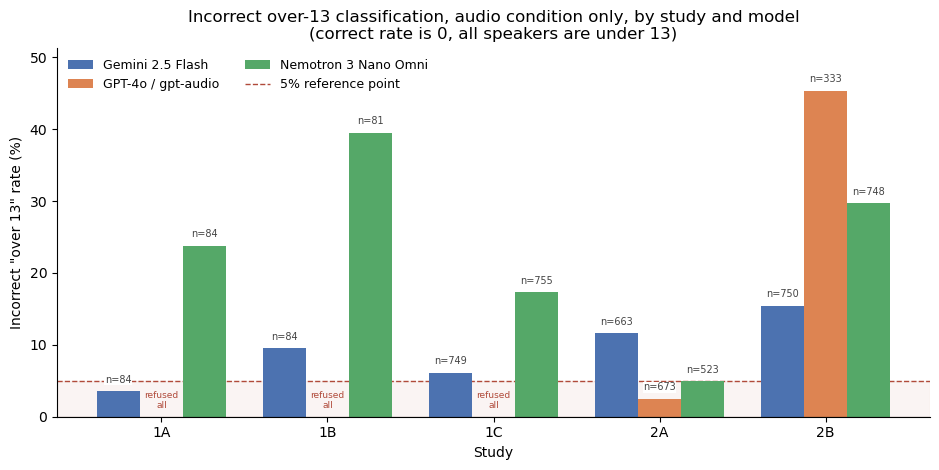

In [14]:
# Grouped bar chart of the incorrect over-13 rate, audio condition only.
order = ['1A', '1B', '1C', '2A', '2B']
models = ['gemini', 'gpt_audio', 'nemotron']
labels = {'gemini': 'Gemini 2.5 Flash',
          'gpt_audio': 'GPT-4o / gpt-audio',
          'nemotron': 'Nemotron 3 Nano Omni'}
colors = {'gemini': '#4C72B0', 'gpt_audio': '#DD8452', 'nemotron': '#55A868'}

REFERENCE_POINT = 5.0   # the over-13 bar stated in the paper

data = {m: [] for m in models}
denom = {m: [] for m in models}
for k in order:
    for m in models:
        if k in raw:
            r = binary_rate(raw[k], m, 'q1_over_13')   # cond defaults to 'audio'
            data[m].append(r['pct_incorrect_yes'])
            denom[m].append(r['n_valid'])
        else:
            data[m].append(float('nan')); denom[m].append(0)

x = np.arange(len(order))
w = 0.26
fig, ax = plt.subplots(figsize=(9.5, 4.8))

# Reference band and line sit behind everything else.
ax.axhspan(0, REFERENCE_POINT, color='#B04A3A', alpha=0.06, zorder=0)
ax.axhline(REFERENCE_POINT, color='#B04A3A', ls='--', lw=1.0, zorder=1,
           label=f'{REFERENCE_POINT:.0f}% reference point')

for j, m in enumerate(models):
    vals = data[m]
    ax.bar(x + (j-1)*w, [0 if np.isnan(v) else v for v in vals], w,
           label=labels[m], color=colors[m], zorder=2)
    for xi, (v, n) in enumerate(zip(vals, denom[m])):
        if not np.isnan(v) and n > 0:
            ax.text(x[xi] + (j-1)*w, v + 0.9, f'n={n}', ha='center', va='bottom',
                    fontsize=7, color='#444', zorder=3,
                    bbox=dict(boxstyle='square,pad=0.05', fc='white', ec='none'))
        else:
            ax.text(x[xi] + (j-1)*w, 0.9, 'refused\nall', ha='center', va='bottom',
                    fontsize=6.5, color='#B04A3A', zorder=3)

ax.axhline(0, color='black', lw=0.8, zorder=2)
ax.set_ylim(0, max(v for m in models for v in data[m] if not np.isnan(v)) + 6)
ax.set_xticks(x); ax.set_xticklabels(order)
ax.set_ylabel('Incorrect "over 13" rate (%)')
ax.set_xlabel('Study')
ax.set_title('Incorrect over-13 classification, audio condition only, by study and model\n'
             '(correct rate is 0, all speakers are under 13)')

# Put the reference-point entry last in the legend.
h, l = ax.get_legend_handles_labels()
ordered = [(hh, ll) for hh, ll in zip(h, l) if 'reference' not in ll] + \
          [(hh, ll) for hh, ll in zip(h, l) if 'reference' in ll]
ax.legend([hh for hh, _ in ordered], [ll for _, ll in ordered],
          frameon=False, fontsize=9, ncol=2, loc='upper left')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.savefig('binary_over13_by_study.png', dpi=200, bbox_inches='tight')
plt.show()

## 13. Audio versus text on the over-13 question

For the two studies with both conditions, 2A and 2B, this shows the incorrect over-13 rate for audio against text, per model. Where the audio bar is far below the text bar, audio is the safer modality on the threshold. Nemotron is expected to break the pattern, since its young-guessing bias produces a low text rate for the wrong reason.

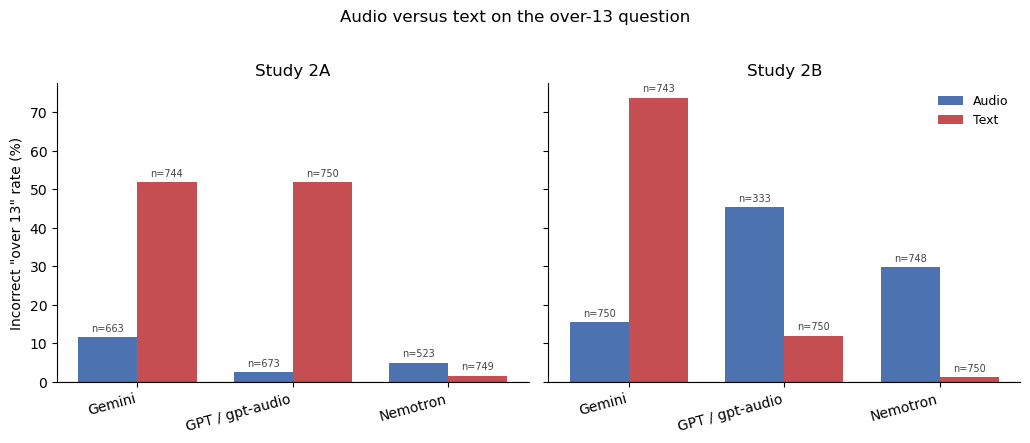

In [13]:
def rate_cond(df, model, cond):
    sub = df[(df['model_norm'] == model) & (df['question'] == 'q1_over_13') & (df['condition'] == cond)]
    preds = sub['response'].apply(parse_yn)
    valid = preds.isin(['YES', 'NO'])
    n = int(valid.sum())
    return (100 * int((preds == 'YES').sum()) / n if n else float('nan'), n)

mstudies = [k for k in ['2A', '2B'] if k in raw]
fig, axes = plt.subplots(1, len(mstudies), figsize=(5.2*len(mstudies), 4.3), sharey=True)
if len(mstudies) == 1:
    axes = [axes]
for ax, k in zip(axes, mstudies):
    df = raw[k]
    x = np.arange(len(models))
    w = 0.38
    a_vals, a_n, t_vals, t_n = [], [], [], []
    for m in models:
        av, an = rate_cond(df, m, 'audio'); tv, tn = rate_cond(df, m, 'text')
        a_vals.append(av); a_n.append(an); t_vals.append(tv); t_n.append(tn)
    ab = ax.bar(x - w/2, [0 if np.isnan(v) else v for v in a_vals], w, label='Audio', color='#4C72B0')
    tb = ax.bar(x + w/2, [0 if np.isnan(v) else v for v in t_vals], w, label='Text', color='#C44E52')
    for xi, (v, n) in enumerate(zip(a_vals, a_n)):
        if not np.isnan(v): ax.text(x[xi]-w/2, v+1, f'n={n}', ha='center', va='bottom', fontsize=7, color='#444')
    for xi, (v, n) in enumerate(zip(t_vals, t_n)):
        if not np.isnan(v): ax.text(x[xi]+w/2, v+1, f'n={n}', ha='center', va='bottom', fontsize=7, color='#444')
    ax.set_xticks(x); ax.set_xticklabels([labels[m] for m in models], rotation=15, ha='right')
    ax.set_title(f'Study {k}')
    ax.spines[['top', 'right']].set_visible(False)
    ax.axhline(0, color='black', lw=0.8)
axes[0].set_ylabel('Incorrect "over 13" rate (%)')
axes[-1].legend(frameon=False, fontsize=9)
fig.suptitle('Audio versus text on the over-13 question', y=1.02)
plt.tight_layout()
plt.savefig('binary_modality_over13.png', dpi=150, bbox_inches='tight')
plt.show()

## 14. Notes for the writeup

The binary questions broadly confirm the age estimation findings, with three exceptions worth carrying into the paper.

The first is Gemini on short conversational audio. On Study 2B audio, Gemini flagged these 8 to 11 year old children as over 13 on 15.5% of clips and as over 18 on 10.9%. The two rates are internally consistent, since the over-18 rate is the lower of the two, but both are high for children this far from either threshold. The model that performed best on the continuous estimate still misjudges the binary thresholds on short audio, which the age estimation framing alone had hidden.

The second is Nemotron on Study 1B, where the binary answer runs ahead of the estimate. Its incorrect over-13 rate reaches 39.5%, even though its own age estimates for those same clips exceed 13 only 8.9% of the time. The two questions disagree on the same responses.

The third is Nemotron on the MyST text condition, where the same contradiction runs the other way and is larger. Its mean text estimate is 14.9 years on Study 2A and 22.4 years on Study 2B, both well above the threshold, yet its incorrect over-13 rate on those same responses is 1.6% and 1.2%. On Study 2B the model reports an average age of 22 years while answering no to the over-13 question on 98.8% of the responses carrying those estimates. This is not a "young guessing" default. The binary answer and the numeric estimate are not connected in either direction.

The dashed line in the figure above is the 5% reference point stated in the paper. Three of the twelve model and study combinations with usable data fall at or below it, and no model falls below it on more than one study.

Two notes on reading the tables: Every rate above uses the audio condition only, since binary_rate now filters to it by default. Pass `cond=None` at any call site to recover the pooled audio and text view. And gpt-audio refused every binary call on the Kids VA studies, so Studies 1A through 1C carry no rate for that model at all, while its Study 2A and 2B cells rest on reduced denominators after refusals and rate limiting. We should report the denominator rather than the percentage alone wherever that model appears.